## Берем датасет Reuters-21578 и достаем из него заголовки                                   

In [ ]:
%pip install -r requirements.txt

In [2]:
import numpy as np
import pandas as pd

In [3]:
import html
import nltk
from nltk.corpus import reuters

nltk.download('reuters')

def load_reuters(split):
    ids = [f for f in reuters.fileids() if f.startswith(split + '/')]
    # ids = ['earn', 'acq', 'crude', 'trade', 'money-fx', 'interest', 'ship']
    texts = [html.unescape(reuters.raw(f)) for f in ids]
    labels = [reuters.categories(f) for f in ids]
    return texts, labels

def clean_text(text):
    text = html.unescape(text)
    title, _, body = text.partition('\n')
    text = f'{title.strip()}. {body}'
    text = TICKER.sub(' ', text)
    text = re.sub(r'[<>]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip().lower()

[nltk_data] Downloading package reuters to /Users/a11111/nltk_data...
[nltk_data]   Package reuters is already up-to-date!


In [4]:
raw_train_texts, raw_train_labels = load_reuters('training')
raw_test_texts, raw_test_labels = load_reuters('test')

In [5]:
import re
TICKER = re.compile(r'<[A-Z]{1,5}(?:\.[A-Z]{1,3})*>')

text_train = [clean_text(t) for t in raw_train_texts]
text_test  = [clean_text(t) for t in raw_test_texts]

def single_label(texts, labels):
    pairs = [(t, l[0]) for t, l in zip(texts, labels) if len(l) == 1]
    return [t for t, _ in pairs], [l for _, l in pairs]

text_train1, tags_train1 = single_label(text_train, raw_train_labels)
text_test1,  tags_test1  = single_label(text_test, raw_test_labels)

In [6]:
print(len(text_train), len(text_test))

7769 3019


In [ ]:
from collections import Counter

counts = Counter(tags_train1)
filtered_text_train1 = [val1 for val1, val2 in zip(text_train1, tags_train1) if counts[val2] >= 5]
filtered_tags_train1 = [val2 for val1, val2 in zip(text_train1, tags_train1) if counts[val2] >= 5] # фильтр чтобы sklearn не ругался на маленькое количество примеров в классах

text_train1, tags_train1 = filtered_text_train1, filtered_tags_train1
print(len(text_train1), len(text_test1))

6545 2583


## Получение эмбеддингов (Bag Of Words)

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

# Полный BoW без фильтрации словаря. Матрица хранится в разреженном формате CSR:
# в памяти лежат только ненулевые счётчики (~0.3% ячеек), поэтому весь корпус занимает единицы МБ.
# Все модели sklearn (TruncatedSVD, LogisticRegression, KNN, KMeans...) принимают такую матрицу напрямую.
vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(text_train1)   # fit только на train
X_test_bow  = vectorizer.transform(text_test1)        # слова, которых нет в словаре train, отбрасываются
vocab = vectorizer.get_feature_names_out()

In [8]:
# Табличный вид BoW: разреженный DataFrame, колонки — слова, строки — документы.
# Обычный pd.DataFrame(X.toarray()) развернул бы все нули и занял ~1.2 ГБ.
bow_df = pd.DataFrame.sparse.from_spmatrix(
    X_train_bow,
    columns=vocab,
    index=[f'{i+1}' for i in range(X_train_bow.shape[0])],
)
print(bow_df.shape, f'{bow_df.memory_usage().sum() / 2**20:.1f} МБ')

# слова первого документа по убыванию частоты
doc = bow_df.iloc[0]
doc[doc > 0].sort_values(ascending=False).head(16)

(6577, 21551) 5.1 МБ


and      23
at       20
the      18
dlrs     14
to       14
for      10
new       9
were      9
york      8
of        8
sales     7
times     7
cocoa     7
in        6
dec       6
are       5
Name: 1, dtype: Sparse[int64, 0]

In [9]:
# Если всё же нужна плотная матрица (numpy-операции, методы без поддержки sparse):
# счётчики маленькие, поэтому хватает uint8 — 1 байт на ячейку вместо 8 (~150 МБ вместо ~1.2 ГБ).
assert X_train_bow.max() <= np.iinfo(np.uint8).max
X_train_dense = X_train_bow.astype(np.uint8).toarray()
print(X_train_dense.shape, f'{X_train_dense.nbytes / 2**20:.0f} МБ')

(6577, 21551) 135 МБ


In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import validation_curve
import numpy as np

pipe = make_pipeline(CountVectorizer(min_df=2, stop_words="english"),
                     Normalizer(), LinearSVC(class_weight="balanced"))
Cs = np.logspace(-3, 2, 11)
tr, va = validation_curve(pipe, text_train1, tags_train1, param_name="linearsvc__C",
                          param_range=Cs, cv=5, scoring="f1_macro")
# рисуй tr.mean(1) и va.mean(1) от Cs с plt.semilogx

/Users/a11111/NLP/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/a11111/NLP/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/a11111/NLP/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/a11111/NLP/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/a11111/NLP/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/a11111/NLP/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: Convergenc

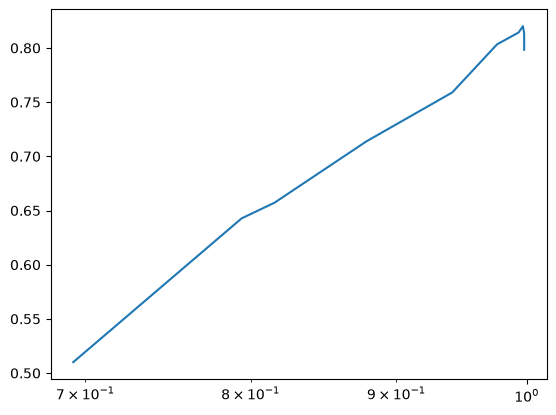

In [31]:
import matplotlib.pyplot as plt

plt.semilogx(tr.mean(1), va.mean(1))


In [32]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn.model_selection import cross_validate

models = {
    "OvR": LinearSVC(C=1),
    "OvO": OneVsOneClassifier(LinearSVC(C=1)),
    "Crammer-Singer": LinearSVC(C=1, multi_class="crammer_singer"),
}

fitted = {}

for name, clf in models.items():
    pipe = make_pipeline(CountVectorizer(min_df=2, stop_words="english"),
                         Normalizer(), clf)
    r = cross_validate(pipe, text_train1, tags_train1, cv=5, scoring="f1_macro")
    fitted[name] = pipe.fit(text_train1, tags_train1)
    print(name, r["test_score"].mean().round(3), r["fit_time"].mean().round(2))

OvR 0.787 0.38
OvO 0.683 1.01


/Users/a11111/NLP/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Crammer-Singer 0.8 1.34


In [44]:
f1.head(3)

,acq,alum,bop,carcass,cocoa,coconut,coffee,copper,cotton,cpi,...,ship,strategic-metal,sugar,tea,tin,trade,veg-oil,wpi,yen,zinc
OvR,0.960965,0.857143,0.823529,0.333333,1.000000,0.0,0.977778,0.888889,1.000000,0.857143,...,0.810811,0.0,0.943396,0.0,0.888889,0.863905,0.761905,0.875000,0.0,0.909091
OvO,0.923606,0.645161,0.750000,0.333333,0.888889,0.0,0.977778,1.000000,0.941176,0.705882,...,0.732394,0.0,0.897959,0.0,0.823529,0.855422,0.842105,0.714286,0.0,0.000000
Crammer-Singer,0.963493,0.833333,0.823529,0.333333,1.000000,0.0,0.977778,0.960000,1.000000,0.857143,...,0.789474,0.0,0.943396,0.0,0.888889,0.869048,0.761905,0.875000,0.0,0.769231


### Берем самые популярные темы

In [61]:
most_common_themes = Counter(tags_train1).most_common(20)
tags, counters = [], []
for theme in most_common_themes:
    tags.append(theme[0])
    counters.append(theme[1])

print([(tag, count) for tag, count in zip(tags,counters)])

[('earn', 2840), ('acq', 1596), ('crude', 253), ('trade', 250), ('money-fx', 222), ('interest', 191), ('money-supply', 123), ('ship', 108), ('sugar', 97), ('coffee', 90), ('gold', 70), ('gnp', 59), ('cpi', 54), ('cocoa', 46), ('grain', 41), ('reserves', 37), ('jobs', 37), ('ipi', 34), ('alum', 31), ('rubber', 31)]


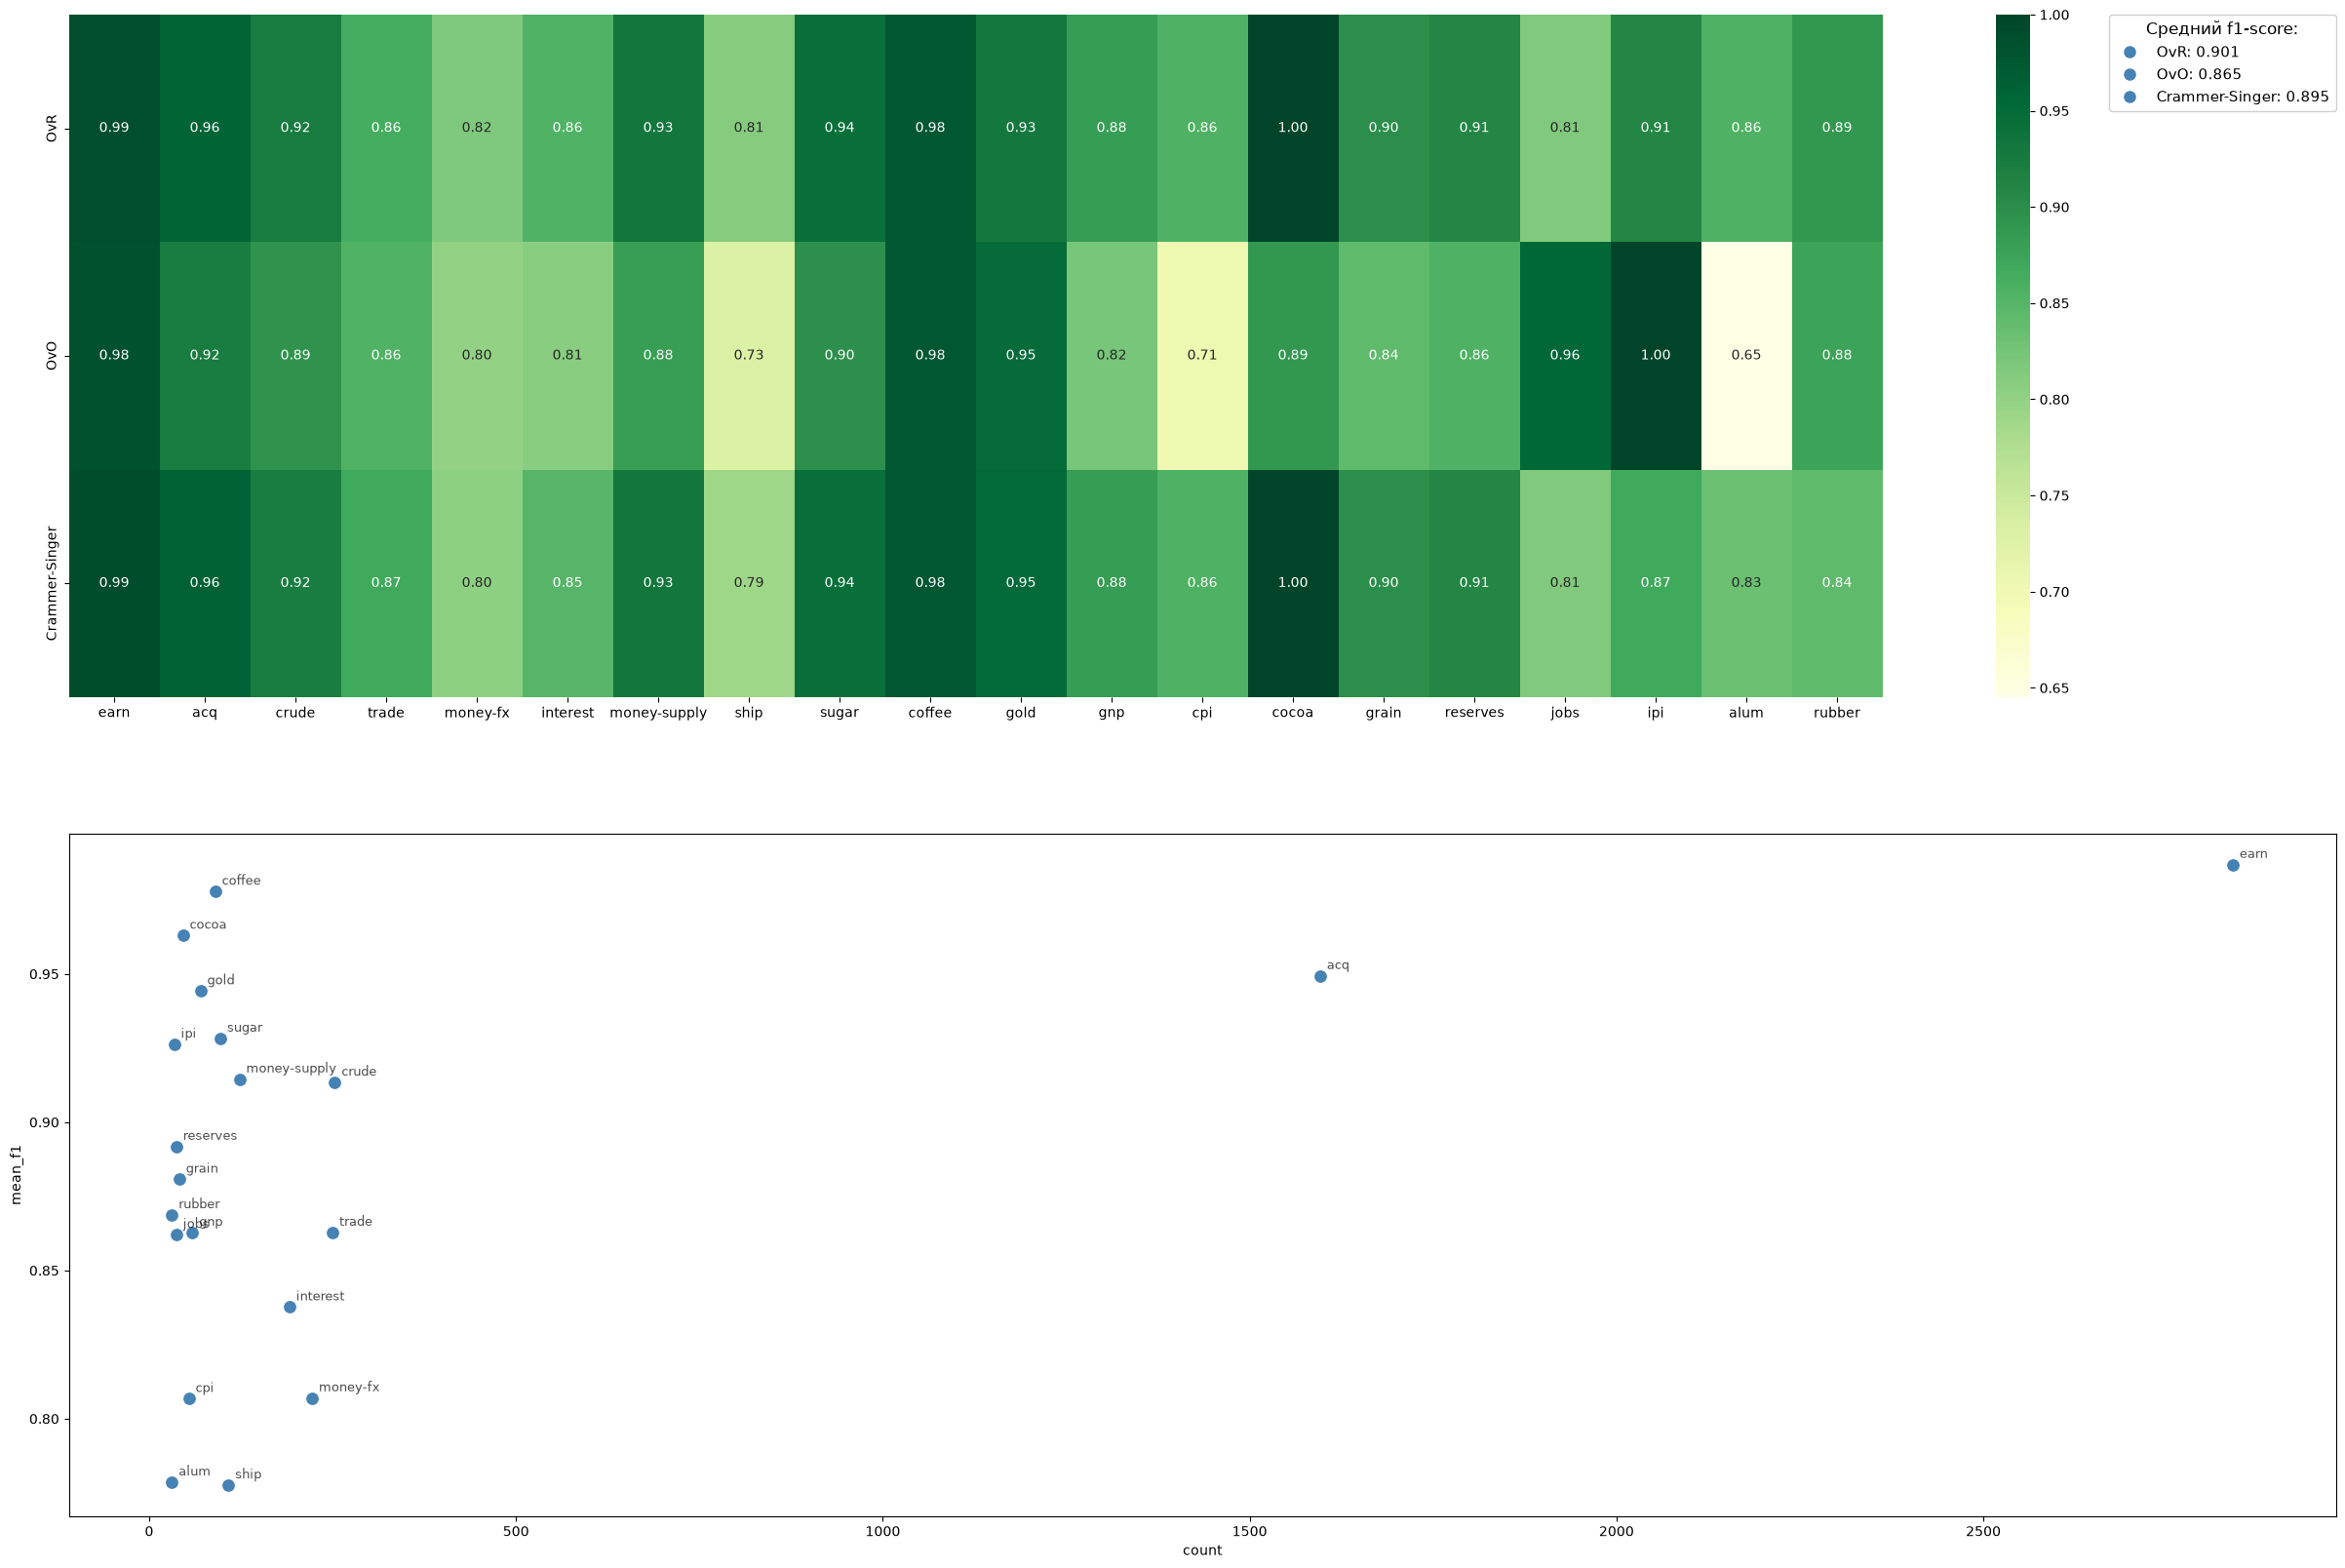

In [ ]:
import pandas as pd, seaborn as sns
from sklearn.metrics import f1_score
from matplotlib.lines import Line2D

# heatmap
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(30, 20))

f1 = pd.DataFrame({name: f1_score(tags_test1, m.predict(text_test1), labels=tags, average=None)
                   for name, m in fitted.items()}, index=tags).T
sns.heatmap(f1, annot=True, fmt=".2f", cmap="YlGn", ax=ax1)

# количество тем в датасете
mean_f1 = f1.mean(axis=0)

plot_df = pd.DataFrame({
    "tag": tags,
    "count": counters,
    "mean_f1": mean_f1.values
})

sns.scatterplot(data=plot_df, x="count", y="mean_f1",
                s=100, ax=ax2, color="steelblue")

for _, row in plot_df.iterrows():
    ax2.annotate(row["tag"], (row["count"], row["mean_f1"]),
                 fontsize=9, alpha=0.7,
                 xytext=(5, 5), textcoords="offset points")

handles = [
    Line2D([], [], linestyle="none", marker="o", markersize=8,
           markerfacecolor="steelblue", markeredgecolor="steelblue"),
    Line2D([], [], linestyle="none", marker="o", markersize=8,
        markerfacecolor="steelblue", markeredgecolor="steelblue"),
    Line2D([], [], linestyle="none", marker="o", markersize=8,
        markerfacecolor="steelblue", markeredgecolor="steelblue"),
]
labels = [
    f"OvR: {f1.loc['OvR'].mean():.3f}",
    f"OvO: {f1.loc['OvO'].mean():.3f}",
    f"Crammer-Singer: {f1.loc['Crammer-Singer'].mean():.3f}",
]

ax1.legend(handles=handles, labels=labels,
           loc="upper right",              
           bbox_to_anchor=(1.25, 1),    
           borderaxespad=0,
           fontsize=11, framealpha=0.9,
           title="Средний f1-score:", title_fontsize=12)

plt.show()